# Step 1: General description of the Quantum Computing sector

| Question (deck, Step 1) | How we measure it here |
|---|---|
| Which technologies make up the field? Which classes dominate, how is the mix shifting? | Fractional counts by **CPC subclass** (with official definitions) and by **WIPO technology field**, over time |
| How big is it, and is it growing, flat or declining? | Families per earliest priority year, applications per filing year; growth (%) and CAGR of the sector **vs all patents** |
| Where is it happening? | Filing offices (IP5); applicant and inventor countries (fractional counts) |
| Patent-heavy or secrecy? | Patent-propensity indicators of the sector **vs a similar field** (AI) and vs all patents, applicant types, plus the literature (Section 9) |

The sector is **not** re-queried: it is the list of DOCDB families produced by Step 0. As in the tutorial every figure is shown at **two levels**, families (inventions) and applications (filings), side by side.

**Contents**: 1 Setup · 2 Sector from Step 0 · 3 Which year? · 4 Methodological choices · 5 Scopes, counting functions, helpers · 6 Volume and growth · 7 Technology mix · 8 Geography · 9 Appropriability · 10 Save the tables for the deck

## 1. Setup and configuration

In [3]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

In [4]:
# ---------------------------------------------------------------- environment
ENV = "PROD"                        # develop on TEST, switch to "PROD" for the final numbers
OUTPUT_DIR = Path("outputs/step1")

# ---------------------------------------------------------------- sector (output of Step 0)
# ----------------------------------------------------------------
# sector (output of Step 0)
SECTOR_NAME = "Quantum computing"

STEP0_DIR = Path("outputs/step0")
STEP0_FILE = STEP0_DIR / f"qc_families_{ENV}.csv"
# ---------------------------------------------------------------- similar field, used in Section 9
COMPARISON_NAME = "Artificial intelligence"
COMPARISON_CPC = ("G06N3/", "G06N5/", "G06N7/", "G06N20/", "Y10S706")   # check against the CPC scheme and validate

# ---------------------------------------------------------------- time window
YEAR_MIN, YEAR_MAX = 2000, 2023     # YEAR_MAX = END_YEAR of Step 0 (the family list stops there)

# Which year to use (Section 3)
FAMILY_TIME_COLUMN = "earliest_filing_year"   # family level: earliest priority year of the family (PW rule)
APPLN_TIME_COLUMN = "appln_filing_year"       # application level: the application's own filing year

# Last years that are still incomplete in PATSTAT, for each choice of year
TRUNCATED_YEARS = {"appln_filing_year": 3, "earliest_filing_year": 3, "earliest_publn_year": 1}

# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                  # patents of invention only (excludes utility models)
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")
TOP_N = 8                                        # categories shown in tables and figures; the rest is "Other"

# ---------------------------------------------------------------- derived
LAST_COMPLETE_YEAR = YEAR_MAX - max(TRUNCATED_YEARS[FAMILY_TIME_COLUMN], TRUNCATED_YEARS[APPLN_TIME_COLUMN])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} | complete years up to {LAST_COMPLETE_YEAR}")

Sector: Quantum computing | env: PROD | years 2000-2023 | complete years up to 2020


## 2. The sector: families from Step 0

A family belongs to the sector if it is in the Step 0 list (CPC/IPC codes OR keywords, validated). At application level we count **all** applications of those families, so the two levels look at the same patents and differ only in *how we count*.

In [5]:
# Load sector family IDs and classification/search flags from Step 0

if not STEP0_FILE.exists():
    raise FileNotFoundError(
        f"Step 0 output not found: {STEP0_FILE.resolve()}"
    )

step0 = pd.read_csv(STEP0_FILE)

required_columns = ["docdb_family_id", "IPC", "CPC", "KW"]

missing_columns = set(required_columns) - set(step0.columns)

if missing_columns:
    raise ValueError(f"Missing columns in Step 0 CSV: {missing_columns}")

step0["docdb_family_id"] = pd.to_numeric(
    step0["docdb_family_id"], errors="coerce"
)

step0 = step0.dropna(subset=["docdb_family_id"]).copy()
step0["docdb_family_id"] = step0["docdb_family_id"].astype(int)

for col in ["IPC", "CPC", "KW"]:
    step0[col] = step0[col].astype(bool)

step0 = step0.drop_duplicates(subset="docdb_family_id")

sector_ids = sorted(step0["docdb_family_id"].unique().tolist())

print(f"Step 0 file: {STEP0_FILE}")
print(f"Families in sector: {len(sector_ids):,}")

display(step0[["IPC", "CPC", "KW"]].value_counts().reset_index(name="families"))

Step 0 file: outputs/step0/qc_families_PROD.csv
Families in sector: 12,833


,IPC,CPC,KW,families
0,True,True,True,6141
1,False,False,True,2754
2,True,True,False,2028
3,True,False,False,748
4,True,False,True,655
5,False,True,False,381
6,False,True,True,126


In [6]:
# These are just examples: write your own functions with your own rules
def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def cpc_family_ids(cpc_prefixes):
    """Query of the docdb_family_ids with at least one CPC symbol starting with one of the prefixes."""
    return (
        db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, cpc_prefixes))
        .distinct()
    )


comparison_ids = cpc_family_ids(COMPARISON_CPC)

## 3. Which year? Three ways to date a patent

| Column | What it is | Use it when… | Incomplete recent years |
|---|---|---|---|
| `appln_filing_year` | year **this application** was filed | you count applications | ~3 years |
| `earliest_publn_year` | year of the **first publication** | you want the most up-to-date series | only the current year |
| `earliest_filing_year` | year of the **earliest priority** (first filing anywhere) | you want the date closest to the invention | ~3 years |

**Family level**: smallest `earliest_filing_year` among the applications of the family (PW rule, same as Step 0). **Application level**: the application's own `appln_filing_year`.

## 4. Other methodological choices

- **Truncation.** The last ~3 years are incomplete (18-month publication lag plus delay in PATSTAT): `LAST_COMPLETE_YEAR` = `YEAR_MAX` − 3 = 2020, the same rule as in Step 0. These years are **shaded in grey in every figure and excluded from growth and from the tables**: a drop there is not a decline of the sector.
- **PCT.** International applications have `appln_auth = 'WO'`. Family level: the family has at least one PCT application. Application level: the application is itself a PCT application.
- **Fractional counting.** A family with 2 Italian and 1 German applicant counts 2/3 for IT and 1/3 for DE (each family sums to 1). Same rule for inventors, CPC subclasses, WIPO fields and applicant types.
- **Missing values.** `person_ctry_code` can be `NULL`, `''` or blanks: they are excluded from country counts and the coverage is reported.
- The same real applicant can have several `person_id`s: harmonisation is Step 2.

## 5. Scopes, counting functions, helpers

A **scope** is a query with one row per counting unit (`unit_id`) and its `year`: family level = `docdb_family_id` and earliest priority year; application level = `appln_id` and filing year. We build {family, application} × {all patents, sector, comparison field}. All calculations run in the database, only small tables are downloaded.

In [7]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


def _restrict(q, family_ids):
    """Keep only the families in family_ids (None = all patents). family_ids: list of ids or a query."""
    if family_ids is None:
        return q
    if isinstance(family_ids, (list, tuple, set)):
        return q.filter(TLS201_APPLN.docdb_family_id.in_(list(family_ids)))
    return q.filter(TLS201_APPLN.docdb_family_id.in_(family_ids.subquery().select()))


def family_scope(family_ids=None):
    """Family level: one row per DOCDB family."""
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    q = db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
        func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, TLS201_APPLN.docdb_family_id > 0)
    return (
        _restrict(q, family_ids)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def application_scope(family_ids=None, time_column=APPLN_TIME_COLUMN):
    """Application level: one row per appln_id, dated by its own time_column."""
    year = getattr(TLS201_APPLN, time_column)
    q = db.query(
        TLS201_APPLN.appln_id.label("unit_id"),
        year.label("year"),
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
        case((TLS201_APPLN.granted == "Y", 1), else_=0).label("is_granted"),
        TLS201_APPLN.docdb_family_size.label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
    return _restrict(q, family_ids).subquery()


@dataclass(frozen=True)
class Scope:
    name: str     # "all patents", the sector or the comparison field
    level: str    # "family" or "application"
    sq: object    # SQLAlchemy subquery, one row per unit


SCOPES = [
    Scope("all patents", "family", family_scope()),
    Scope(SECTOR_NAME, "family", family_scope(sector_ids)),
    Scope("all patents", "application", application_scope()),
    Scope(SECTOR_NAME, "application", application_scope(sector_ids)),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]   # family first, then application

In [8]:
def _join_applications(q, scope):
    """Join the applications of each unit: all applications of a family, or the application itself."""
    key = TLS201_APPLN.docdb_family_id if scope.level == "family" else TLS201_APPLN.appln_id
    return q.join(TLS201_APPLN, key == scope.sq.c.unit_id).filter(TLS201_APPLN.ipr_type == IPR_TYPE)


def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def count_per_year(scope, only_pct=False):
    """Number of units (families or applications) per year; only_pct keeps those via PCT."""
    sq = scope.sq
    q = db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
    if only_pct:
        q = q.filter(sq.c.is_pct == 1)
    return _tag(patstat.df(q), scope)


def _split_equally(scope, unit_category, category):
    """Fractional counting: each unit is split equally across its distinct categories (sums to 1)."""
    pairs = unit_category.distinct().subquery()
    k = db.query(pairs.c.unit_id, func.count().label("k")).group_by(pairs.c.unit_id).subquery()
    q = (
        db.query(getattr(pairs.c, category), pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == pairs.c.unit_id)
        .group_by(getattr(pairs.c, category), pairs.c.year)
    )
    return _tag(patstat.df(q), scope)


def fractional_by_person(scope, attr, role="applicant"):
    """Fractional counts by a person attribute (country, sector...) and year.

    Each unit is split among its distinct persons with a known value of the attribute.
    """
    sq = scope.sq
    seq_nr = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    persons = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS207_PERS_APPLN.person_id, attr.label("category")).distinct(), scope
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(seq_nr > 0, attr.isnot(None), attr != "")
        .subquery()
    )
    k = db.query(persons.c.unit_id, func.count().label("k")).group_by(persons.c.unit_id).subquery()
    q = (
        db.query(persons.c.category, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == persons.c.unit_id)
        .group_by(persons.c.category, persons.c.year)
    )
    return _tag(patstat.df(q), scope).assign(role=role)


def fractional_by_country(scope, role="applicant"):
    """Unknown countries are NULL, '' or blanks: trimmed and excluded."""
    return fractional_by_person(scope, func.trim(TLS206_PERSON.person_ctry_code), role).rename(columns={"category": "ctry"})


def fractional_by_cpc_subclass(scope):
    """Fractional counts by CPC subclass (first 4 characters) and year."""
    sq = scope.sq
    subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
    q = (
        _join_applications(db.query(sq.c.unit_id, sq.c.year, subclass.label("subclass")), scope)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    )
    return _split_equally(scope, q, "subclass")


def fractional_by_techn_field(scope):
    """Fractional counts by WIPO technology field (1-35) and year (tls230 weights rescaled to sum 1 per unit)."""
    sq = scope.sq
    unit_field = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                     func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w")),
            scope,
        )
        .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
        .group_by(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr)
        .subquery()
    )
    unit_total = (
        db.query(unit_field.c.unit_id, func.sum(unit_field.c.w).label("w_total"))
        .group_by(unit_field.c.unit_id)
        .subquery()
    )
    q = (
        db.query(unit_field.c.techn_field_nr, unit_field.c.year,
                 func.sum(unit_field.c.w / unit_total.c.w_total).label("n_frac"))
        .join(unit_total, unit_total.c.unit_id == unit_field.c.unit_id)
        .group_by(unit_field.c.techn_field_nr, unit_field.c.year)
    )
    return _tag(patstat.df(q), scope)


def count_by_office(scope):
    """Units per office and year (family level: families with at least one application at the office)."""
    sq = scope.sq
    q = (
        _join_applications(
            db.query(TLS201_APPLN.appln_auth.label("office"), sq.c.year,
                     func.count(distinct(sq.c.unit_id)).label("n")),
            scope,
        )
        .group_by(TLS201_APPLN.appln_auth, sq.c.year)
    )
    return _tag(patstat.df(q), scope)


def scope_profile(scope):
    """Patent-propensity indicators on the complete years: units, via PCT, granted, in 2+ applications, family size."""
    sq = scope.sq
    q = db.query(
        func.count().label("n"),
        func.sum(sq.c.is_pct).label("n_pct"),
        func.sum(sq.c.is_granted).label("n_granted"),
        func.sum(case((sq.c.family_size > 1, 1), else_=0)).label("n_multi"),
        func.avg(sq.c.family_size * 1.0).label("mean_family_size"),
    ).filter(sq.c.year <= LAST_COMPLETE_YEAR)
    return _tag(patstat.df(q), scope)

In [9]:
def shade_truncated(ax):
    """Shade the incomplete (truncated) years on a time axis."""
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0, label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories (over the complete years) and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in every column, with 'Other' last and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # no grey: grey = "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    """Two axes: families (left) and applications (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

## 6. Volume: how big is the sector, and is it growing?

Families and applications per year, and how many go through the PCT. The gap between the two curves is the average number of applications per invention. Grey = incomplete years.

**Deck figure 1**: families over time with the truncated years shaded (left panel).

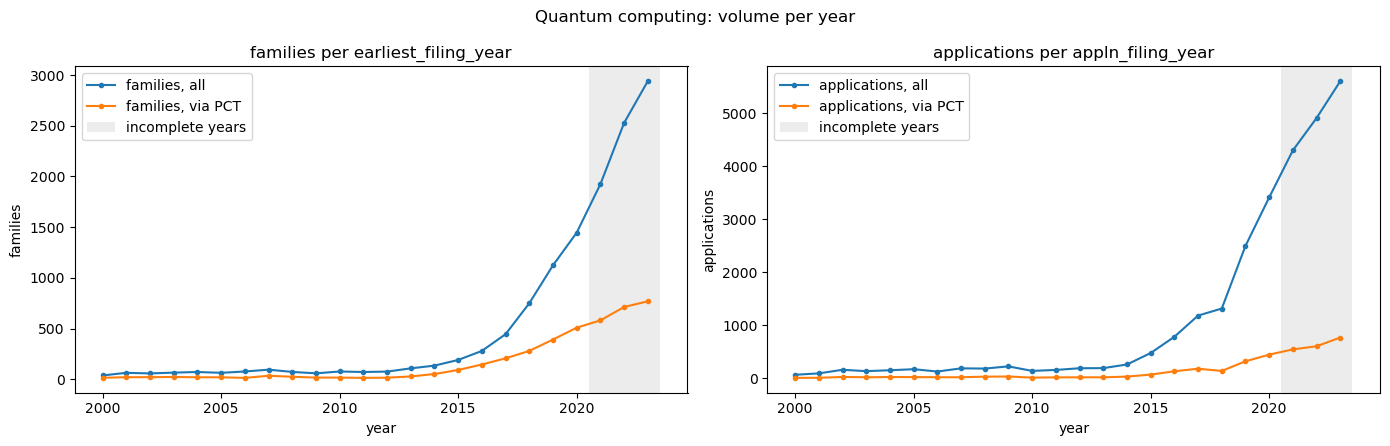

In [10]:
volume = pd.concat(
    [count_per_year(s).assign(series="all") for s in SCOPES]
    + [count_per_year(s, only_pct=True).assign(series="via PCT") for s in SCOPES],
    ignore_index=True,
)

fig, axes = side_by_side(f"{SECTOR_NAME}: volume per year", sharex=True)
for ax, scope in zip(axes, SECTOR_SCOPES):
    data = volume.query("scope == @scope.name and level == @scope.level")
    for series, grp in data.groupby("series"):
        ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=f"{UNIT_LABEL[scope.level]}, {series}")
    shade_truncated(ax)
    year_col = FAMILY_TIME_COLUMN if scope.level == "family" else APPLN_TIME_COLUMN
    ax.set(title=f"{UNIT_LABEL[scope.level]} per {year_col}", xlabel="year", ylabel=UNIT_LABEL[scope.level])
    ax.legend()
plt.tight_layout()
plt.show()

### 6.1 The same sector, three ways to date it

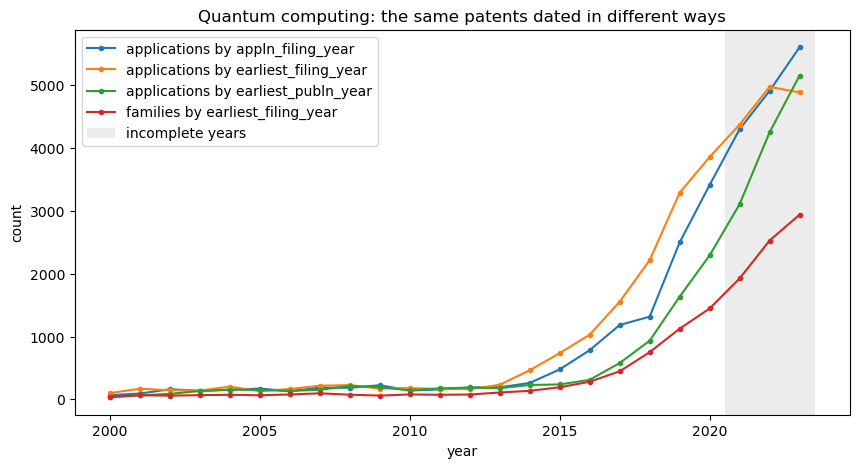

In [11]:
dating = pd.concat(
    [
        count_per_year(Scope(SECTOR_NAME, "application", application_scope(sector_ids, col)))
        .assign(series=f"applications by {col}")
        for col in ("appln_filing_year", "earliest_publn_year", "earliest_filing_year")
    ]
    + [volume.query("scope == @SECTOR_NAME and level == 'family' and series == 'all'")
       .assign(series=f"families by {FAMILY_TIME_COLUMN}")],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(10, 5))
for series, grp in dating.groupby("series"):
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=series)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: the same patents dated in different ways", xlabel="year", ylabel="count")
ax.legend()
plt.show()

### 6.2 Growth: is the sector growing faster than patenting as a whole?

- **sector growth (%)** = (count in the last complete year − count in the first year) / count in the first year × 100;
- **growth of all patents (%)**: same formula on all unique families / applications of PATSTAT in the same window;
- **CAGR (%)**: compound annual growth rate over the same years, easier to compare across windows.

Incomplete years are excluded. A small sector moves a lot from year to year: read the curve, not only the two end points. The share of the sector in all patents shows whether it is **gaining weight**.

In [12]:
start, end = YEAR_MIN, LAST_COMPLETE_YEAR
totals = volume.query("series == 'all'").pivot_table(index="year", columns=["level", "scope"], values="n")

growth = pd.DataFrame({
    f"count in {start}": totals.loc[start],
    f"count in {end}": totals.loc[end],
    f"growth {start}-{end} (%)": (totals.loc[end] / totals.loc[start] - 1) * 100,
    f"CAGR {start}-{end} (%)": ((totals.loc[end] / totals.loc[start]) ** (1 / (end - start)) - 1) * 100,
}).loc[[(lvl, s) for lvl in LEVELS for s in ("all patents", SECTOR_NAME)]]

growth.style.format({f"count in {start}": "{:,.0f}", f"count in {end}": "{:,.0f}",
                     f"growth {start}-{end} (%)": "{:+.1f}%", f"CAGR {start}-{end} (%)": "{:+.1f}%"})

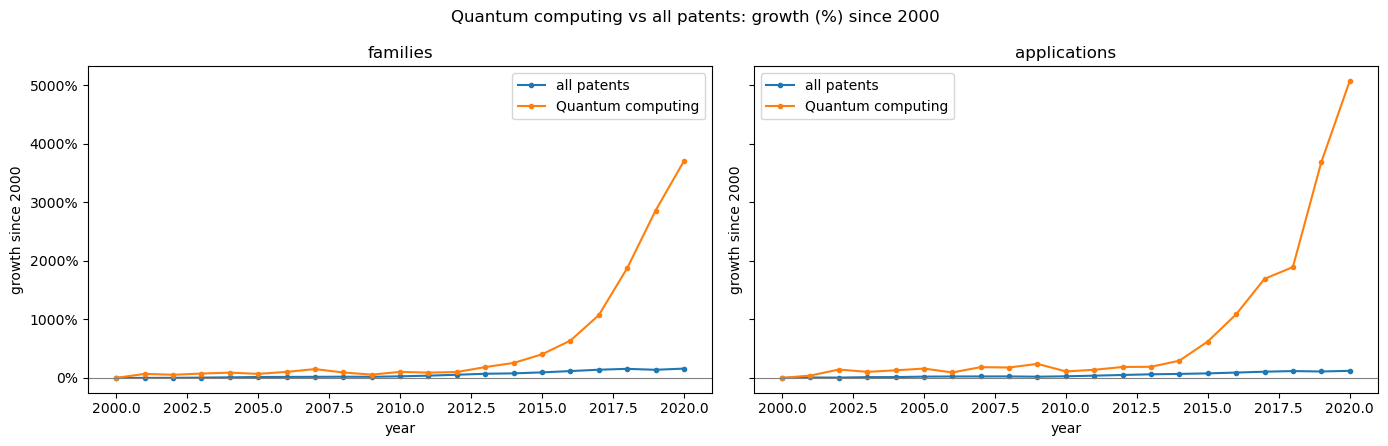

In [13]:
# Growth (%) of each year with respect to the first year: sector vs all patents
growth_path = (totals.loc[start:end] / totals.loc[start] - 1) * 100

fig, axes = side_by_side(f"{SECTOR_NAME} vs all patents: growth (%) since {start}", sharey=True)
for ax, level in zip(axes, LEVELS):
    for scope_name in ("all patents", SECTOR_NAME):
        ax.plot(growth_path.index, growth_path[(level, scope_name)], marker="o", ms=3, label=scope_name)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(title=UNIT_LABEL[level], xlabel="year", ylabel=f"growth since {start}")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()
plt.tight_layout()
plt.show()

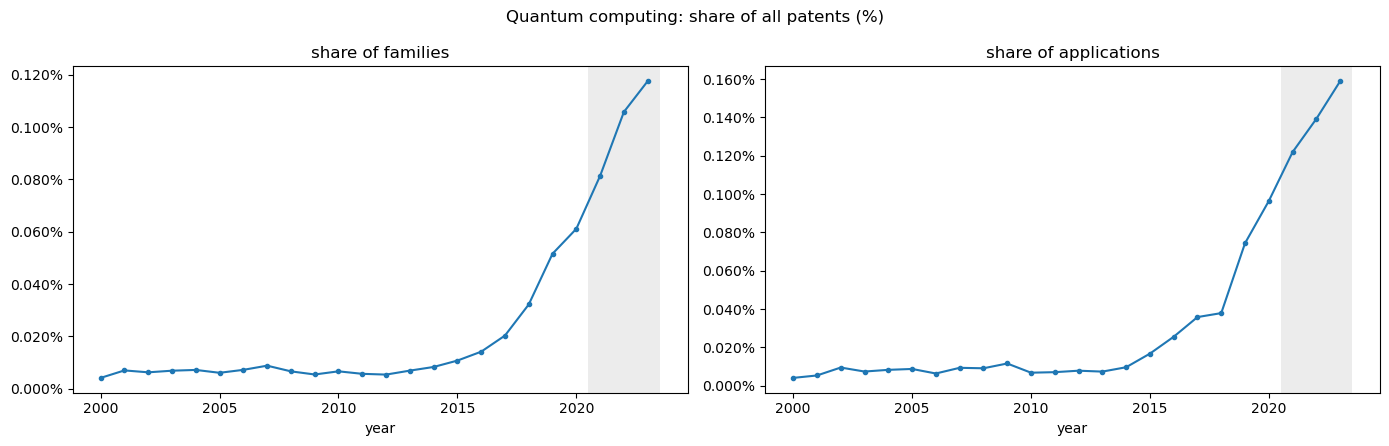

,family,application
year,,
2000,0.0042,0.0041
2005,0.0061,0.0088
2010,0.0067,0.0068
2015,0.0108,0.0168
2020,0.0611,0.0964


In [14]:
# Share of the sector in all patents (gaining or losing weight?)
sector_share = pd.DataFrame({lvl: totals[(lvl, SECTOR_NAME)] / totals[(lvl, "all patents")] * 100 for lvl in LEVELS})

fig, axes = side_by_side(f"{SECTOR_NAME}: share of all patents (%)", sharex=True)
for ax, level in zip(axes, LEVELS):
    ax.plot(sector_share.index, sector_share[level], marker="o", ms=3)
    shade_truncated(ax)
    ax.set(title=f"share of {UNIT_LABEL[level]}", xlabel="year")
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=3))
plt.tight_layout()
plt.show()
sector_share.loc[[y for y in sector_share.index if y % 5 == 0 or y == LAST_COMPLETE_YEAR]].round(4)

## 7. Technology mix

### 7.1 CPC subclasses

Which subclasses dominate and how is the mix shifting? Each family (application) is split equally across its CPC subclasses, so shares sum to 100%.

Read the result with care: the sector is *defined* by `G06N10/`, so `G06N` is high by construction. The informative part is the **co-classification**: which neighbouring technologies the field draws on (software `G06F`, communication `H04L`/`H04B`, hardware `H10N`/`H10D`/`B82Y`...) and how the weights move.

**Deck table and figure**: top CPC subclasses with official definitions, and the mix over time.

In [15]:
cpc_mix = pd.concat([fractional_by_cpc_subclass(s) for s in SECTOR_SCOPES], ignore_index=True)
cpc_pooled = pd.concat([pool_other(cpc_mix[cpc_mix["level"] == lvl], "subclass").assign(level=lvl)
                        for lvl in LEVELS], ignore_index=True)

cpc_counts = complete_years(cpc_pooled).pivot_table(index="subclass", columns="level", values="n_frac",
                                                    aggfunc="sum", fill_value=0)[list(LEVELS)]
cpc_shares = share_table(cpc_counts)

# how is the mix shifting? families, first half vs second half of the complete years
mid = (YEAR_MIN + LAST_COMPLETE_YEAR) // 2
fam_pooled = cpc_pooled[cpc_pooled["level"] == "family"]


def period_share(lo, hi):
    d = fam_pooled[fam_pooled["year"].between(lo, hi)].groupby("subclass")["n_frac"].sum()
    return d / d.sum() * 100


cpc_shares[f"families {YEAR_MIN}-{mid} (%)"] = period_share(YEAR_MIN, mid)
cpc_shares[f"families {mid + 1}-{LAST_COMPLETE_YEAR} (%)"] = period_share(mid + 1, LAST_COMPLETE_YEAR)
cpc_shares["change (p.p.)"] = cpc_shares.iloc[:, -1] - cpc_shares.iloc[:, -2]

In [16]:
# Titles from the CPC scheme (https://www.cooperativepatentclassification.org): CHECK each one, and add the subclasses
# of your top list that are missing (a missing one is shown as "(look up in the CPC scheme)").
CPC_TITLES = {
    "G06N": "Computing arrangements based on specific computational models (incl. G06N10 quantum computing)",
    "G06F": "Electric digital data processing",
    "H04L": "Transmission of digital information, e.g. telegraphic communication",
    "H04B": "Transmission",
    "B82Y": "Specific uses or applications of nanostructures; measurement or analysis of nanostructures; manufacture or treatment of nanostructures",
    "H10N": "Electric solid-state devices not otherwise provided for (incl. superconducting devices)",
    "H10D": "Inorganic electric semiconductor devices",
    "H01L": "Semiconductor devices; electric solid-state devices not otherwise provided for",
    "G06Q": "ICT specially adapted for administrative, commercial, financial, managerial or supervisory purposes",
    "Y02D": "Climate change mitigation technologies in information and communication technologies",
    "G06E": "Optical computing devices; computing devices using other radiations with similar properties",
    "G06T": "Image data processing or generation, in general",
    "G01R": "Measuring electric variables; measuring magnetic variables",
    "H03K": "Pulse technique",
    "H03M": "Coding; decoding; code conversion in general",
    "G02F": "Devices or arrangements for the control of light by changing the optical properties of a medium",
}
cpc_shares["definition"] = [CPC_TITLES.get(s, "(look up in the CPC scheme)") if s not in ("Other", "Total") else ""
                            for s in cpc_shares.index]

num_cols = [c for c in cpc_shares.columns if c != "definition"]
display(cpc_shares.style.format("{:.1f}", subset=num_cols).set_properties(subset=["definition"], **{"text-align": "left"}))

level,family,application,families 2000-2010 (%),families 2011-2020 (%),change (p.p.),definition
subclass,,,,,,
G06N,30.2,27.9,23.4,31.1,7.7,Computing arrangements based on specific computational models (incl. G06N10 quantum computing)
G06F,12.4,11.8,2.4,13.8,11.4,Electric digital data processing
H04L,10.2,7.3,7.2,10.6,3.5,"Transmission of digital information, e.g. telegraphic communication"
B82Y,8.4,10.3,27.8,5.7,-22.1,Specific uses or applications of nanostructures; measurement or analysis of nanostructures; manufacture or treatment of nanostructures
H10N,5.3,7.3,3.7,5.5,1.8,Electric solid-state devices not otherwise provided for (incl. superconducting devices)
H04B,2.8,2.3,2.4,2.9,0.4,Transmission
H03K,2.6,3.8,2.7,2.5,-0.1,Pulse technique
H10D,2.3,2.7,3.4,2.2,-1.2,Inorganic electric semiconductor devices
Other,25.8,26.4,27.0,25.6,-1.4,


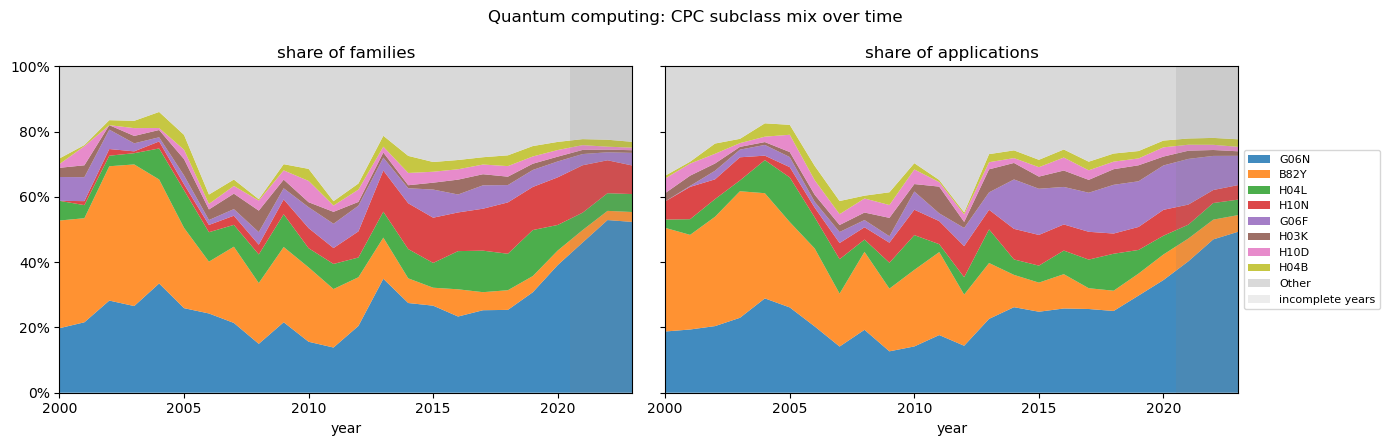

In [17]:
fig, axes = side_by_side(f"{SECTOR_NAME}: CPC subclass mix over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    stack_100(ax, share_over_time(cpc_pooled[cpc_pooled["level"] == level], "subclass"),
              f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

### 7.2 WIPO technology fields

WIPO groups all patents into **35 technology fields**, which belong to **5 technology sectors** (Electrical engineering, Instruments, Chemistry, Mechanical engineering, Other fields; tables `tls230` + `tls901`). Coarser than CPC, the same for every sector. *Of 100 sector families, how many are in each technology sector?*

In [18]:
field_names = patstat.df(
    db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_field,
             TLS901_TECHN_FIELD_IPC.techn_sector).distinct()
).drop_duplicates("techn_field_nr")

fields = (
    pd.concat([fractional_by_techn_field(s) for s in SECTOR_SCOPES], ignore_index=True)
    .merge(field_names, on="techn_field_nr", how="left")
)
for col in ("techn_field", "techn_sector"):
    fields[col] = fields[col].str.strip()

techn_sector_counts = complete_years(fields).pivot_table(index="techn_sector", columns="level", values="n_frac",
                                                         aggfunc="sum", fill_value=0)[list(LEVELS)]
techn_sector_shares = share_table(techn_sector_counts)
pct_format(techn_sector_shares)

level,family,application
techn_sector,,
Electrical engineering,86.7%,87.5%
Instruments,7.7%,6.7%
Chemistry,4.6%,4.6%
Mechanical engineering,0.8%,0.9%
Other fields,0.2%,0.2%
Total,100.0%,100.0%


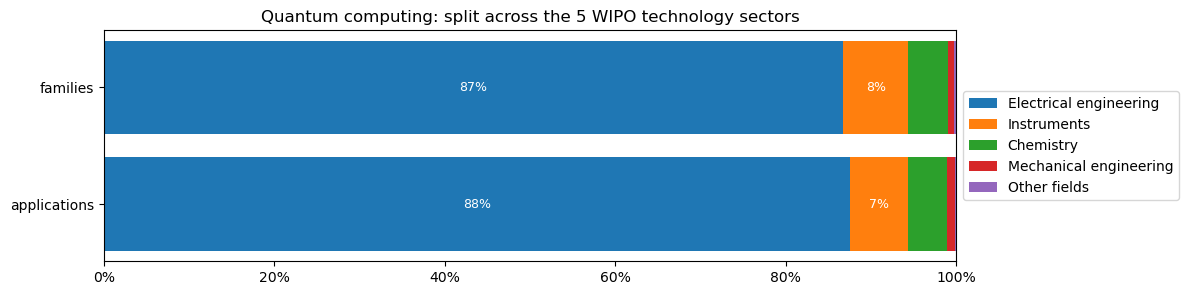

In [19]:
# One bar per level, split into the 5 technology sectors (each bar = 100%)
bars = techn_sector_shares.drop("Total").T

fig, ax = plt.subplots(figsize=(11, 3))
left = np.zeros(len(bars))
for techn_sector in bars.columns:
    values = bars[techn_sector].values
    ax.barh([UNIT_LABEL[l] for l in bars.index], values, left=left, label=techn_sector)
    for y, (x0, v) in enumerate(zip(left, values)):
        if v >= 5:
            ax.text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += values
ax.set(title=f"{SECTOR_NAME}: split across the 5 WIPO technology sectors", xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

In [20]:
# The same split at the level of the 35 fields (largest fields, the rest in "Other")
field_counts = complete_years(fields).pivot_table(index="techn_field", columns="level", values="n_frac",
                                                  aggfunc="sum", fill_value=0)[list(LEVELS)]
top_fields = field_counts["family"].nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()
pct_format(share_table(field_counts))

level,family,application
techn_field,,
Computer technology,50.9%,50.6%
Semiconductors,12.9%,18.0%
Digital communication,11.4%,7.7%
Basic communication processes,4.0%,5.1%
Telecommunications,3.8%,3.4%
Optics,3.4%,3.1%
Micro-structural and nano-technology,2.8%,3.2%
Measurement,2.7%,2.2%
Other,7.9%,6.7%


## 8. Geography

### 8.1 Filing offices: the IP5

`EP` EPO · `US` USPTO · `CN` CNIPA · `JP` JPO · `KR` KIPO, plus `WO` (PCT) and Other.

- **Application level**: each application is at one office, shares sum to 100%.
- **Family level**: a family is usually filed at several offices, so the counts overlap and **do not** sum to the number of families: counts, not shares ("how many inventions are protected at each office").

In [21]:
offices = pd.concat([count_by_office(s) for s in SECTOR_SCOPES], ignore_index=True)
offices["office"] = offices["office"].str.strip()
offices["office"] = offices["office"].where(offices["office"].isin(IP5_OFFICES + ("WO",)), "Other")
offices = offices.groupby(["level", "office", "year"], as_index=False)["n"].sum()

# Application level: shares across offices (sum to 100%)
office_counts = complete_years(offices.query("level == 'application'")).groupby("office")["n"].sum().to_frame("applications")
office_shares = share_table(office_counts)
print(f"Share of the sector's applications filed at the IP5: {office_shares.loc[list(IP5_OFFICES), 'applications'].sum():.1f}%")
pct_format(office_shares)

Share of the sector's applications filed at the IP5: 72.1%


,applications
office,
US,29.3%
CN,18.8%
WO,13.1%
JP,10.0%
EP,9.9%
KR,4.1%
Other,14.8%
Total,100.0%


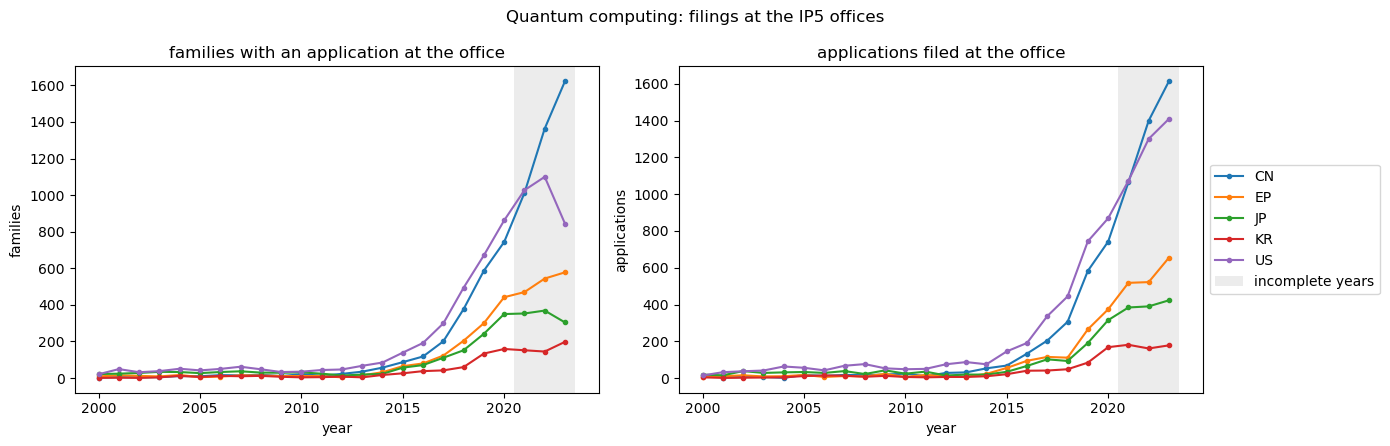

In [22]:
fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")
    for office, g in data.groupby("office"):
        ax.plot(g["year"], g["n"], marker="o", ms=3, label=office)
    shade_truncated(ax)
    title = ("families with an application at the office" if level == "family"
             else "applications filed at the office")
    ax.set(title=title, xlabel="year", ylabel=UNIT_LABEL[level])
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### 8.2 Applicant and inventor countries (fractional counts)

Applicant country = where the *owners* are; inventor country = where the *research* is done. **Watch out for missing values**: the coverage (share of the sector's units with a known country) is printed, and the shares are on the known ones only.

In [23]:
countries = pd.concat(
    [fractional_by_country(s, role) for s in SECTOR_SCOPES for role in ("applicant", "inventor")],
    ignore_index=True,
)

# coverage: units with a known country / all units of the sector (complete years)
n_units = {s.level: int(complete_years(volume.query("scope == @SECTOR_NAME and series == 'all' and level == @s.level"))["n"].sum())
           for s in SECTOR_SCOPES}
for (level, role), g in complete_years(countries).groupby(["level", "role"]):
    print(f"{level:12s} {role:10s}: known country for {g['n_frac'].sum() / n_units[level]:.1%} of the units")

country_counts = complete_years(countries).pivot_table(index="ctry", columns=["level", "role"], values="n_frac",
                                                       aggfunc="sum", fill_value=0)
country_counts = country_counts[[(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]]
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()
pct_format(share_table(country_counts))

application  applicant : known country for 69.2% of the units
application  inventor  : known country for 63.6% of the units
family       applicant : known country for 71.0% of the units
family       inventor  : known country for 69.9% of the units


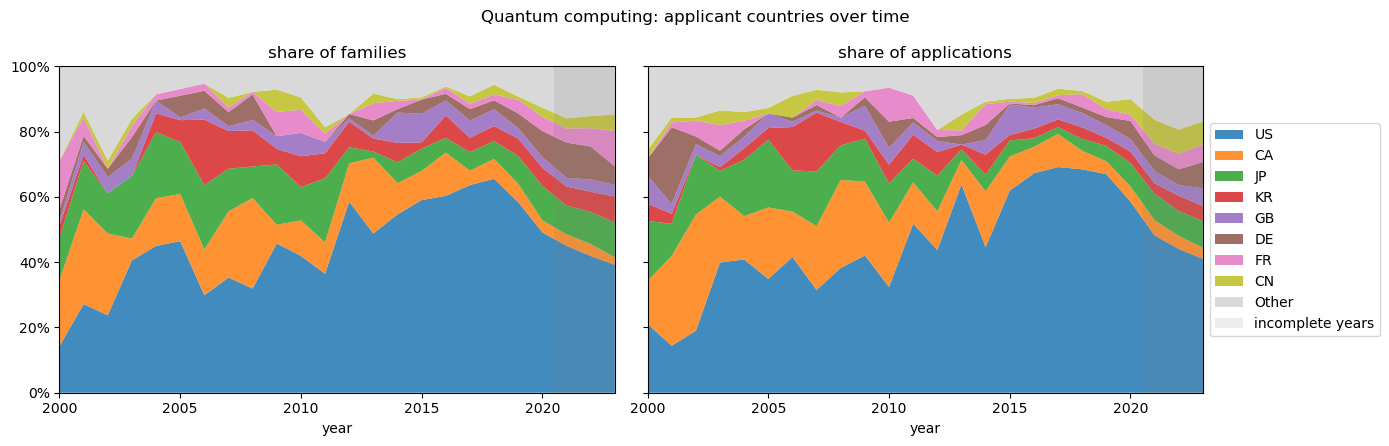

In [24]:
fig, axes = side_by_side(f"{SECTOR_NAME}: applicant countries over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = countries.query("role == 'applicant' and level == @level")
    stack_100(ax, share_over_time(pool_other(data.rename(columns={"ctry": "country"}), "country"), "country"),
              f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 9. Appropriability: is the field patent-heavy or does it rely on secrecy?

PATSTAT only sees what **is** patented, so secrecy cannot be measured directly. We triangulate (slides: *compare the sector with other evidence on patents vs secrecy*):

1. **Revealed patent propensity**, compared with a similar field (`COMPARISON_NAME`) and with all patents: how much of the sector's inventions are pushed through costly routes (PCT, several offices, many applications per invention) and how many get granted. Higher values = protection valued enough to pay for it.
2. **Who patents**: the applicant types (companies vs universities vs individuals). Universities and public labs patent for licensing and spin-offs; firms in a fast-moving, hardest-to-reverse-engineer know-how business may also rely on secrecy.
3. **Literature** (below), the main evidence on secrecy.

*Caveat*: all these indicators are on the complete years only and describe patented inventions; a low propensity is **consistent with** secrecy, it does not prove it.

In [25]:
SCOPES_CMP = [
    Scope("all patents", "family", SCOPES[0].sq),
    Scope(SECTOR_NAME, "family", SCOPES[1].sq),
    Scope(COMPARISON_NAME, "family", family_scope(comparison_ids)),
    Scope("all patents", "application", SCOPES[2].sq),
    Scope(SECTOR_NAME, "application", SCOPES[3].sq),
    Scope(COMPARISON_NAME, "application", application_scope(comparison_ids)),
]

profile = pd.concat([scope_profile(s) for s in SCOPES_CMP], ignore_index=True).set_index(["level", "scope"])
indicators = pd.DataFrame({
    f"units (years <= {LAST_COMPLETE_YEAR})": profile["n"],
    "via PCT (%)": profile["n_pct"] / profile["n"] * 100,
    "granted (%)": profile["n_granted"] / profile["n"] * 100,
    "in a family with 2+ applications (%)": profile["n_multi"] / profile["n"] * 100,
    "mean applications per family": profile["mean_family_size"],
})
indicators.style.format({indicators.columns[0]: "{:,.0f}", "via PCT (%)": "{:.1f}%", "granted (%)": "{:.1f}%",
                         "in a family with 2+ applications (%)": "{:.1f}%", "mean applications per family": "{:.2f}"})

Read it by **level**. At family level the PCT share, the share of multi-application families and the mean family size say how far inventions are taken abroad. Note that `granted` is a *any application granted* flag at family level and a per-application flag at application level, and that grants lag filings: compare the three rows of the same level, not the levels with each other.

level,family,application
applicant_type,,
COMPANY,55.3%,66.1%
UNIVERSITY,21.5%,15.3%
INDIVIDUAL,9.9%,8.2%
UNKNOWN,7.9%,5.9%
GOV NON-PROFIT,4.5%,4.0%
GOV NON-PROFIT UNIVERSITY,0.9%,0.4%
COMPANY UNIVERSITY,0.0%,0.0%
Total,100.0%,100.0%


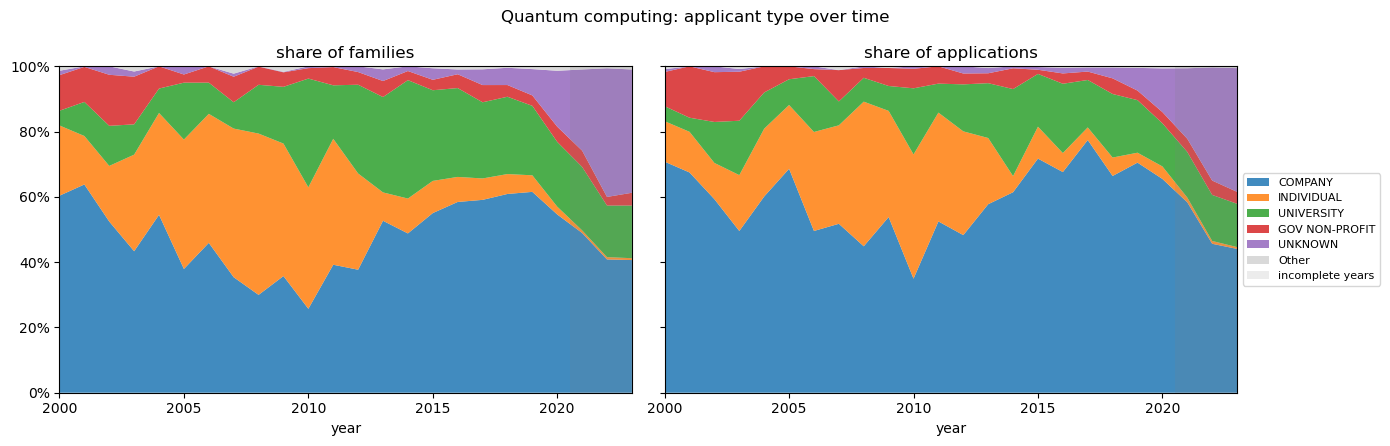

In [26]:
# Who patents: applicant type (PATSTAT psn_sector), fractional counts
app_type = pd.concat(
    [fractional_by_person(s, func.trim(TLS206_PERSON.psn_sector), "applicant") for s in SECTOR_SCOPES],
    ignore_index=True,
).rename(columns={"category": "applicant_type"})
app_type["applicant_type"] = app_type["applicant_type"].replace({"": "UNKNOWN"})

type_counts = complete_years(app_type).pivot_table(index="applicant_type", columns="level", values="n_frac",
                                                   aggfunc="sum", fill_value=0)[list(LEVELS)]
display(pct_format(share_table(type_counts)))

fig, axes = side_by_side(f"{SECTOR_NAME}: applicant type over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    stack_100(ax, share_over_time(pool_other(app_type[app_type["level"] == level], "applicant_type", n=5), "applicant_type"),
              f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

### 9.1 Literature and argued paragraph

**Where to look** (verify each reference and its exact claims on Google Scholar before citing; the ones marked ✔ were found while preparing this notebook, the others are standard references on appropriability from memory):

- ✔ Lenarczyk, G., Minssen, T., Aboy, M., *IP in Superposition: Patents, Trade Secrets, and Open Innovation in Quantum Information Technology* (book chapter, Springer; abstract on EconPapers/RePEc). Argues that firms combine patents, trade secrets and open innovation across the layers of the quantum stack; patent filings have grown a lot, but secrecy stays important because of tacit know-how and export controls.
- ✔ Practitioner commentary (law firms, *not* academic, use only as supporting evidence): Hannes Snellman, *Quantum Computing, Part 2: IP in the Quantum Age*; Mondaq, *Quantum Computing and IP Law in the US*; Berkeley Center for Law & Technology, *Protecting Quantum Innovation*. They describe a *layered* strategy and the difficulty of patenting quantum algorithms (US §101 eligibility after *Alice v. CLS Bank*; enablement and written description).
- General appropriability literature: Levin, Klevorick, Nelson & Winter (1987, *Brookings Papers*); Cohen, Nelson & Walsh (2000, NBER WP 7552), *Protecting Their Intellectual Assets*; Arundel (2001, *Research Policy*), on when secrecy is rated above patents; Hall, Helmers, Rogers & Sena (2014, *Journal of Economic Literature*), *The Choice between Formal and Informal IP*.

**Draft paragraph** (replace the brackets with the numbers of Sections 6-9, and keep only what your data supports):

> Quantum computing firms appear to protect their inventions with a *layered* strategy rather than with patents or secrecy alone. On the patent side the evidence is strong: families grew at [X]% per year between [YEAR_MIN] and [LAST_COMPLETE_YEAR], [N] times faster than all patents, and [Y]% of them go through the PCT and [Z]% are filed in several offices, [above/in line with/below] the [AI] benchmark. [Universities and public labs account for [U]% of applicants, which is consistent with a science-based field where patents also serve licensing and spin-offs.] On the secrecy side the literature suggests that part of the value sits in tacit, hard-to-codify know-how (device fabrication, calibration, control software) and in algorithms that are difficult to patent (e.g. US §101 eligibility), so firms keep these as trade secrets and disclose through patents the architectures and methods that competitors could reverse-engineer or that investors and partners need to see (Lenarczyk et al.; Cohen, Nelson & Walsh 2000). Export-control rules on quantum technologies can also discourage early disclosure. Patent counts therefore measure the *disclosed* part of the innovation effort, and our figures are a lower bound of the field's activity.

## 10. Save the tables for the deck

In [27]:
volume.to_csv(OUTPUT_DIR / f"volume_{ENV}.csv", index=False)
growth.to_csv(OUTPUT_DIR / f"growth_{ENV}.csv")
cpc_shares.to_csv(OUTPUT_DIR / f"cpc_subclass_table_{ENV}.csv")
techn_sector_shares.to_csv(OUTPUT_DIR / f"wipo_sectors_{ENV}.csv")
office_shares.to_csv(OUTPUT_DIR / f"offices_{ENV}.csv")
country_counts.to_csv(OUTPUT_DIR / f"countries_{ENV}.csv")
indicators.to_csv(OUTPUT_DIR / f"appropriability_indicators_{ENV}.csv")
print("saved in", OUTPUT_DIR.resolve())

saved in /home/jovyan/outputs/step1
